
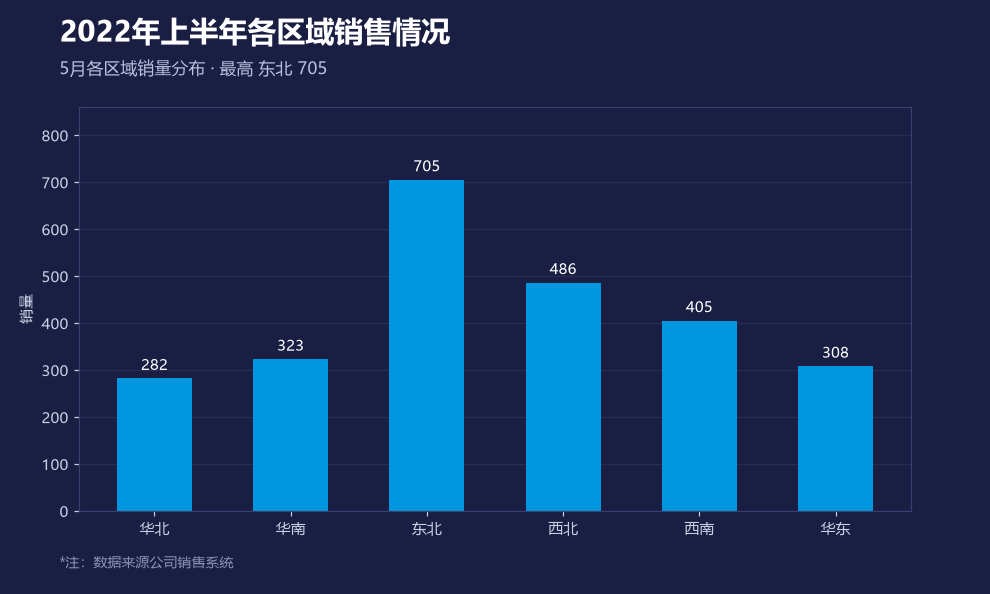

In [1]:
import numpy as np, pandas as pd, plotly.graph_objects as go, plotly, shutil, base64
from pathlib import Path
from IPython.display import HTML, display
BG,FG,GY,DIM,LINE='#1A1E43','#FFFFFF','#C9CFE3','#8B93B8','#39406F'
OUT=Path('interactive');OUT.mkdir(exist_ok=True)
if not (OUT/'plotly.min.js').exists(): shutil.copy(Path(plotly.__file__).parent/'package_data'/'plotly.min.js', OUT/'plotly.min.js')
def L(t,s,n,**kw):
    d=dict(paper_bgcolor=BG,plot_bgcolor=BG,height=620,
      font=dict(family='Microsoft YaHei, SimHei, sans-serif',color=GY,size=12),
      title=dict(text='<b>'+t+'</b><br><span style="font-size:13px;color:#B8C1DE">'+s+'</span>',x=.045,y=.935,xanchor='left',font=dict(color=FG,size=20)),
      margin=dict(l=70,r=45,t=118,b=82),
      hoverlabel=dict(bgcolor='#252B5C',bordercolor=LINE,font=dict(color=FG,size=12)),
      legend=dict(bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY)),
      annotations=[dict(text=n,x=0,y=-.17,xref='paper',yref='paper',showarrow=False,font=dict(color=DIM,size=10),xanchor='left')],
      transition=dict(duration=420,easing='cubic-in-out'))
    d.update(kw);return d
def A(**kw):
    d=dict(gridcolor=LINE,zerolinecolor=LINE,linecolor=LINE,tickfont=dict(color=GY),title=dict(font=dict(color=GY)),showgrid=True)
    d.update(kw);return d
def P():
    return dict(bgcolor=BG,angularaxis=dict(visible=False,showgrid=False,showline=False,direction='clockwise',rotation=0),
                radialaxis=dict(visible=False,showgrid=False,range=[0,1.06]))
def M(labels,args,active=0,x=1,y=1.13):
    return [dict(active=active,buttons=[dict(label=a,method='restyle',args=b) for a,b in zip(labels,args)],
      x=x,y=y,xanchor='right',bgcolor='#252B5C',bordercolor=LINE,borderwidth=1,font=dict(color=FG,size=11),pad=dict(l=6,r=6,t=3,b=3))]
def arc(v,vmax,i,c,lbl,step,width=15,n=44):
    w=180*v/vmax;th=[w*k/(n-1) for k in range(n)]
    return go.Scatterpolar(theta=th,r=[1-i*step]*n,mode='lines',line=dict(color=c,width=width),
      name=lbl,text=[lbl]*n,hovertemplate='%{text}<extra></extra>',showlegend=True)
def show(f,name):
    sh='<script>window.Plotly=window.Plotly||window.moduleName;</script>'
    cfg=dict(displaylogo=False,responsive=True,scrollZoom=True)
    frag=f.to_html(full_html=False,include_plotlyjs=False,config=cfg,div_id='p'+name)
    lib=(OUT/'plotly.min.js').read_text(encoding='utf-8')
    full='<!doctype html><html><head><meta charset="utf-8"><script>'+lib+'</script>'+sh+'<style>body{margin:0;background:'+BG+'}</style></head><body>'+frag+'</body></html>'
    (OUT/('ix'+name+'.html')).write_text(full,encoding='utf-8')
    p=Path('dyn'+name+'.png')
    im='<img src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'" style="width:100%;max-width:1000px;display:block">' if p.exists() else ''
    tip='<div style="color:#B8C1DE;font:12px Microsoft YaHei;padding:9px">交互版：interactive/ix'+name+'.html ｜ 用浏览器打开 dashboard.html 可切换全部 7 张交互图</div>'
    h=('<div style="background:'+BG+';padding:6px;border-radius:8px;position:relative">'
       '<div id="iv'+name+'"><script src="interactive/plotly.min.js"></script>'+sh+frag+'</div>'
       '<div id="fb'+name+'" style="position:absolute;top:0;left:0;right:0;background:'+BG+'">'+im+tip+'</div></div>'
       '<script>setTimeout(function(){var f=document.getElementById("fb'+name+'");'
       'if(f&&document.querySelector("#iv'+name+' .main-svg"))f.style.display="none"},700)</script>')
    display(HTML(h))
REG=['华北','华南','东北','西北','西南','华东']
MO=['1月','2月','3月','4月','5月','6月']
V=[[259,247,705,513,463,384],[235,266,529,324,579,282],[330,342,705,540,492,308],
   [282,342,599,270,492,384],[282,323,705,486,405,308],[965,380,282,567,463,897]]
t0=V[4]
f=go.Figure(go.Bar(x=REG,y=t0,marker_color='#0097E0',marker_line=dict(color='#00C2FF',width=1),
  text=[str(q) for q in t0],textposition='outside',textfont=dict(color=FG,size=11),name='销量',
  hovertemplate='<b>%{x}</b><br>销量 %{y}<extra></extra>'),
  frames=[go.Frame(name=MO[j],traces=[0],data=[dict(type='bar',y=V[j],text=[str(q) for q in V[j]])]) for j in range(6)])
f.update_layout(L('2022年上半年各区域销售情况','拖动滑块 / 点击播放 · 组合框选月份（INDEX + MATCH）','*注：数据来源公司销售系统',
  xaxis=A(showgrid=False,title='区域'),yaxis=A(title='销量',range=[0,max(max(q) for q in V)*1.18]),
  margin=dict(l=70,r=45,t=118,b=138),hovermode='x',showlegend=False,
  sliders=[dict(active=4,x=.11,y=-.11,len=.84,xanchor='left',bgcolor='#252B5C',bordercolor=LINE,
    tickcolor=GY,font=dict(color=GY,size=10),currentvalue=dict(prefix='月份：',font=dict(color='#FFC000',size=12),visible=True),
    steps=[dict(label=MO[j],method='animate',args=[[MO[j]],dict(mode='immediate',frame=dict(duration=420,redraw=False),transition=dict(duration=420))]) for j in range(6)])],
  updatemenus=[dict(type='buttons',showactive=False,x=.02,y=-.22,xanchor='left',bgcolor='#252B5C',bordercolor=LINE,font=dict(color=FG,size=11),
    buttons=[dict(label='播放',method='animate',args=[None,dict(frame=dict(duration=520,redraw=False),transition=dict(duration=420),fromcurrent=True)]),
             dict(label='暂停',method='animate',args=[[None],dict(frame=dict(duration=0,redraw=False),mode='immediate',transition=dict(duration=0))])])]))
f.layout.annotations[0].update(y=-.31)
show(f,'01')



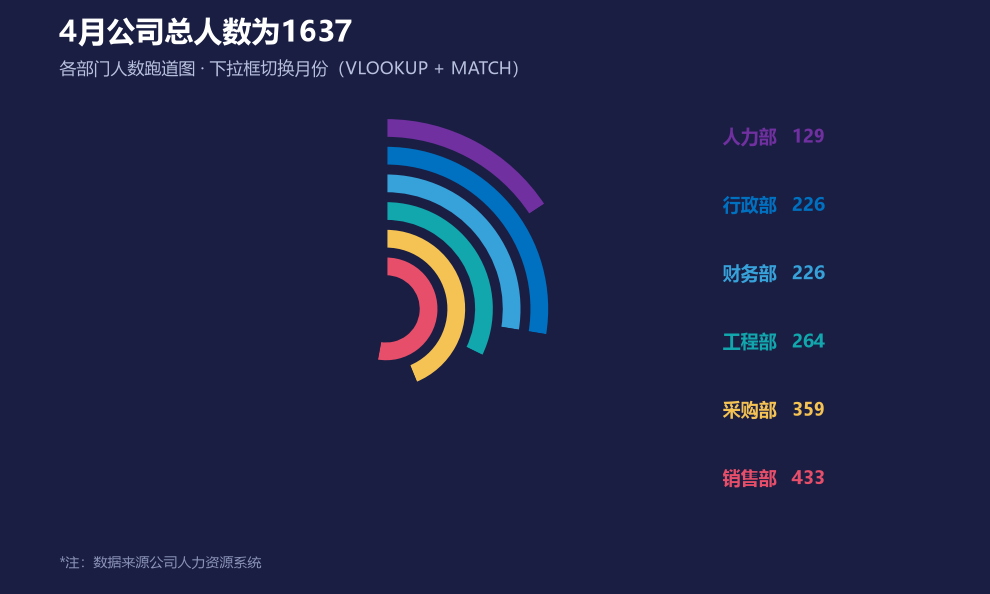

In [2]:
import numpy as np, pandas as pd, plotly.graph_objects as go, plotly, shutil, base64
from pathlib import Path
from IPython.display import HTML, display
BG,FG,GY,DIM,LINE='#1A1E43','#FFFFFF','#C9CFE3','#8B93B8','#39406F'
OUT=Path('interactive');OUT.mkdir(exist_ok=True)
if not (OUT/'plotly.min.js').exists(): shutil.copy(Path(plotly.__file__).parent/'package_data'/'plotly.min.js', OUT/'plotly.min.js')
def L(t,s,n,**kw):
    d=dict(paper_bgcolor=BG,plot_bgcolor=BG,height=620,
      font=dict(family='Microsoft YaHei, SimHei, sans-serif',color=GY,size=12),
      title=dict(text='<b>'+t+'</b><br><span style="font-size:13px;color:#B8C1DE">'+s+'</span>',x=.045,y=.935,xanchor='left',font=dict(color=FG,size=20)),
      margin=dict(l=70,r=45,t=118,b=82),
      hoverlabel=dict(bgcolor='#252B5C',bordercolor=LINE,font=dict(color=FG,size=12)),
      legend=dict(bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY)),
      annotations=[dict(text=n,x=0,y=-.17,xref='paper',yref='paper',showarrow=False,font=dict(color=DIM,size=10),xanchor='left')],
      transition=dict(duration=420,easing='cubic-in-out'))
    d.update(kw);return d
def A(**kw):
    d=dict(gridcolor=LINE,zerolinecolor=LINE,linecolor=LINE,tickfont=dict(color=GY),title=dict(font=dict(color=GY)),showgrid=True)
    d.update(kw);return d
def P():
    return dict(bgcolor=BG,angularaxis=dict(visible=False,showgrid=False,showline=False,direction='clockwise',rotation=0),
                radialaxis=dict(visible=False,showgrid=False,range=[0,1.06]))
def M(labels,args,active=0,x=1,y=1.13):
    return [dict(active=active,buttons=[dict(label=a,method='restyle',args=b) for a,b in zip(labels,args)],
      x=x,y=y,xanchor='right',bgcolor='#252B5C',bordercolor=LINE,borderwidth=1,font=dict(color=FG,size=11),pad=dict(l=6,r=6,t=3,b=3))]
def arc(v,vmax,i,c,lbl,step,width=15,n=44):
    w=180*v/vmax;th=[w*k/(n-1) for k in range(n)]
    return go.Scatterpolar(theta=th,r=[1-i*step]*n,mode='lines',line=dict(color=c,width=width),
      name=lbl,text=[lbl]*n,hovertemplate='%{text}<extra></extra>',showlegend=True)
def show(f,name):
    sh='<script>window.Plotly=window.Plotly||window.moduleName;</script>'
    cfg=dict(displaylogo=False,responsive=True,scrollZoom=True)
    frag=f.to_html(full_html=False,include_plotlyjs=False,config=cfg,div_id='p'+name)
    lib=(OUT/'plotly.min.js').read_text(encoding='utf-8')
    full='<!doctype html><html><head><meta charset="utf-8"><script>'+lib+'</script>'+sh+'<style>body{margin:0;background:'+BG+'}</style></head><body>'+frag+'</body></html>'
    (OUT/('ix'+name+'.html')).write_text(full,encoding='utf-8')
    p=Path('dyn'+name+'.png')
    im='<img src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'" style="width:100%;max-width:1000px;display:block">' if p.exists() else ''
    tip='<div style="color:#B8C1DE;font:12px Microsoft YaHei;padding:9px">交互版：interactive/ix'+name+'.html ｜ 用浏览器打开 dashboard.html 可切换全部 7 张交互图</div>'
    h=('<div style="background:'+BG+';padding:6px;border-radius:8px;position:relative">'
       '<div id="iv'+name+'"><script src="interactive/plotly.min.js"></script>'+sh+frag+'</div>'
       '<div id="fb'+name+'" style="position:absolute;top:0;left:0;right:0;background:'+BG+'">'+im+tip+'</div></div>'
       '<script>setTimeout(function(){var f=document.getElementById("fb'+name+'");'
       'if(f&&document.querySelector("#iv'+name+' .main-svg"))f.style.display="none"},700)</script>')
    display(HTML(h))
DEP=['人力部','行政部','财务部','工程部','采购部','销售部']
MO=['1月','2月','3月','4月']
D=[[130,138,130,129],[226,206,217,226],[238,228,255,226],[293,305,314,264],[326,349,316,359],[451,456,406,433]]
CL=['#7030A0','#0070C0','#37A2DA','#11A7AD','#F5C353','#E74E69']
def pack(j):
    tot=sum(d[j] for d in D)
    return tot,[arc(D[i][j],500,i,CL[i],DEP[i]+'  '+str(D[i][j]),.145) for i in range(6)]
tot,tr=pack(3)
f=go.Figure(tr,layout=L('4月公司总人数为'+str(tot),'各部门人数跑道图 · 下拉框切换月份（VLOOKUP + MATCH）',
  '*注：数据来源公司人力资源系统',height=700,margin=dict(l=40,r=40,t=100,b=72),polar=P(),showlegend=True,
  legend=dict(x=.99,y=.9,bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY,size=11)),
  updatemenus=M(MO,[[{'theta':[q.theta for q in pack(j)[1]],'text':[q.text for q in pack(j)[1]],'name':[q.name for q in pack(j)[1]]},list(range(6))] for j in range(4)],active=3)))
show(f,'02')



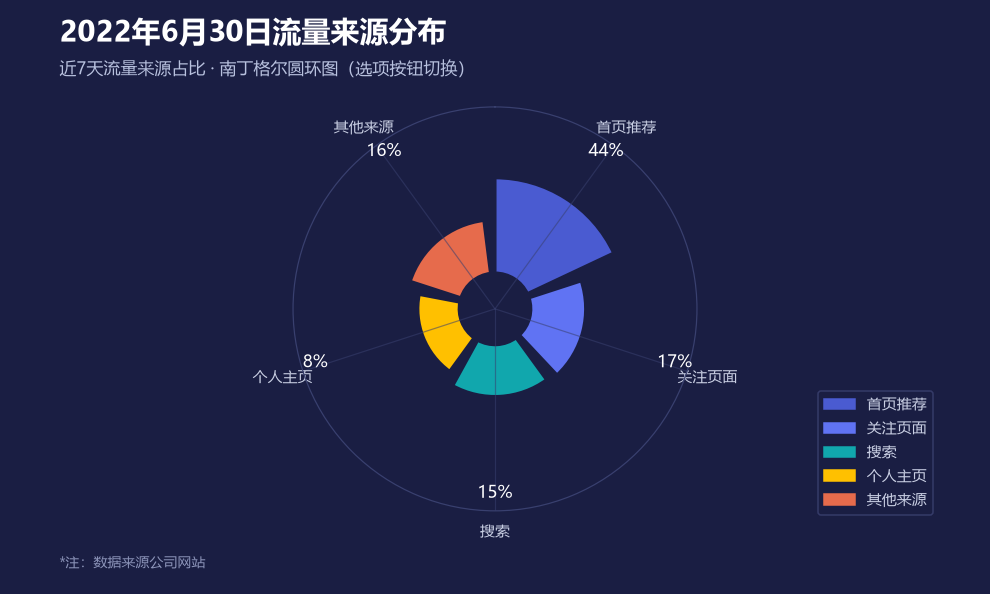

In [3]:
import numpy as np, pandas as pd, plotly.graph_objects as go, plotly, shutil, base64
from pathlib import Path
from IPython.display import HTML, display
BG,FG,GY,DIM,LINE='#1A1E43','#FFFFFF','#C9CFE3','#8B93B8','#39406F'
OUT=Path('interactive');OUT.mkdir(exist_ok=True)
if not (OUT/'plotly.min.js').exists(): shutil.copy(Path(plotly.__file__).parent/'package_data'/'plotly.min.js', OUT/'plotly.min.js')
def L(t,s,n,**kw):
    d=dict(paper_bgcolor=BG,plot_bgcolor=BG,height=620,
      font=dict(family='Microsoft YaHei, SimHei, sans-serif',color=GY,size=12),
      title=dict(text='<b>'+t+'</b><br><span style="font-size:13px;color:#B8C1DE">'+s+'</span>',x=.045,y=.935,xanchor='left',font=dict(color=FG,size=20)),
      margin=dict(l=70,r=45,t=118,b=82),
      hoverlabel=dict(bgcolor='#252B5C',bordercolor=LINE,font=dict(color=FG,size=12)),
      legend=dict(bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY)),
      annotations=[dict(text=n,x=0,y=-.17,xref='paper',yref='paper',showarrow=False,font=dict(color=DIM,size=10),xanchor='left')],
      transition=dict(duration=420,easing='cubic-in-out'))
    d.update(kw);return d
def A(**kw):
    d=dict(gridcolor=LINE,zerolinecolor=LINE,linecolor=LINE,tickfont=dict(color=GY),title=dict(font=dict(color=GY)),showgrid=True)
    d.update(kw);return d
def P():
    return dict(bgcolor=BG,angularaxis=dict(visible=False,showgrid=False,showline=False,direction='clockwise',rotation=0),
                radialaxis=dict(visible=False,showgrid=False,range=[0,1.06]))
def M(labels,args,active=0,x=1,y=1.13):
    return [dict(active=active,buttons=[dict(label=a,method='restyle',args=b) for a,b in zip(labels,args)],
      x=x,y=y,xanchor='right',bgcolor='#252B5C',bordercolor=LINE,borderwidth=1,font=dict(color=FG,size=11),pad=dict(l=6,r=6,t=3,b=3))]
def arc(v,vmax,i,c,lbl,step,width=15,n=44):
    w=180*v/vmax;th=[w*k/(n-1) for k in range(n)]
    return go.Scatterpolar(theta=th,r=[1-i*step]*n,mode='lines',line=dict(color=c,width=width),
      name=lbl,text=[lbl]*n,hovertemplate='%{text}<extra></extra>',showlegend=True)
def show(f,name):
    sh='<script>window.Plotly=window.Plotly||window.moduleName;</script>'
    cfg=dict(displaylogo=False,responsive=True,scrollZoom=True)
    frag=f.to_html(full_html=False,include_plotlyjs=False,config=cfg,div_id='p'+name)
    lib=(OUT/'plotly.min.js').read_text(encoding='utf-8')
    full='<!doctype html><html><head><meta charset="utf-8"><script>'+lib+'</script>'+sh+'<style>body{margin:0;background:'+BG+'}</style></head><body>'+frag+'</body></html>'
    (OUT/('ix'+name+'.html')).write_text(full,encoding='utf-8')
    p=Path('dyn'+name+'.png')
    im='<img src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'" style="width:100%;max-width:1000px;display:block">' if p.exists() else ''
    tip='<div style="color:#B8C1DE;font:12px Microsoft YaHei;padding:9px">交互版：interactive/ix'+name+'.html ｜ 用浏览器打开 dashboard.html 可切换全部 7 张交互图</div>'
    h=('<div style="background:'+BG+';padding:6px;border-radius:8px;position:relative">'
       '<div id="iv'+name+'"><script src="interactive/plotly.min.js"></script>'+sh+frag+'</div>'
       '<div id="fb'+name+'" style="position:absolute;top:0;left:0;right:0;background:'+BG+'">'+im+tip+'</div></div>'
       '<script>setTimeout(function(){var f=document.getElementById("fb'+name+'");'
       'if(f&&document.querySelector("#iv'+name+' .main-svg"))f.style.display="none"},700)</script>')
    display(HTML(h))
SRC=['首页推荐','关注页面','搜索','个人主页','其他来源']
P7={'近7天':[.44,.17,.15,.08,.16],'近30天':[.38,.21,.15,.09,.17]}
CL=['#4A5BD1','#6073F3','#11A7AD','#FFC000','#E66B4C']
def rv(k): return [q*2.3+.45 for q in P7[k]]
def tx(k): return [s+'<br><b>'+format(p,'.0%')+'</b>' for s,p in zip(SRC,P7[k])]
def pc(k): return [format(p,'.0%') for p in P7[k]]
TH=[i*72+36 for i in range(5)]
f=go.Figure()
f.add_trace(go.Barpolar(theta=TH,r=rv('近7天'),width=[70]*5,base=.55,
  marker=dict(color=CL,line=dict(color=BG,width=2)),customdata=tx('近7天'),
  hovertemplate='%{customdata}<extra></extra>',name='流量来源'))
f.add_trace(go.Scatterpolar(theta=TH,r=[2.25]*5,mode='text',text=pc('近7天'),
  textfont=dict(color=FG,size=13,family='Microsoft YaHei'),hoverinfo='skip',showlegend=False))
def args(k):
    return [{'r':[rv(k),[2.25]*5],'customdata':[tx(k),['']*5],'text':[pc(k),pc(k)]},[0,1]]
f.update_layout(L('2022年6月30日流量来源分布','下拉框切换周期 · 南丁格尔圆环图（悬停查看占比）','*注：数据来源公司网站',
  height=700,margin=dict(l=40,r=40,t=100,b=72),
  polar=dict(bgcolor=BG,angularaxis=dict(rotation=90,direction='clockwise',tickvals=TH,
    ticktext=SRC,gridcolor=LINE,linecolor=LINE,tickfont=dict(color=GY,size=11),showgrid=True),
    radialaxis=dict(visible=False,range=[0,2.6],showgrid=False)),
  showlegend=False,
  updatemenus=M(['近7天','近30天'],[args(k) for k in ['近7天','近30天']])))
show(f,'03')



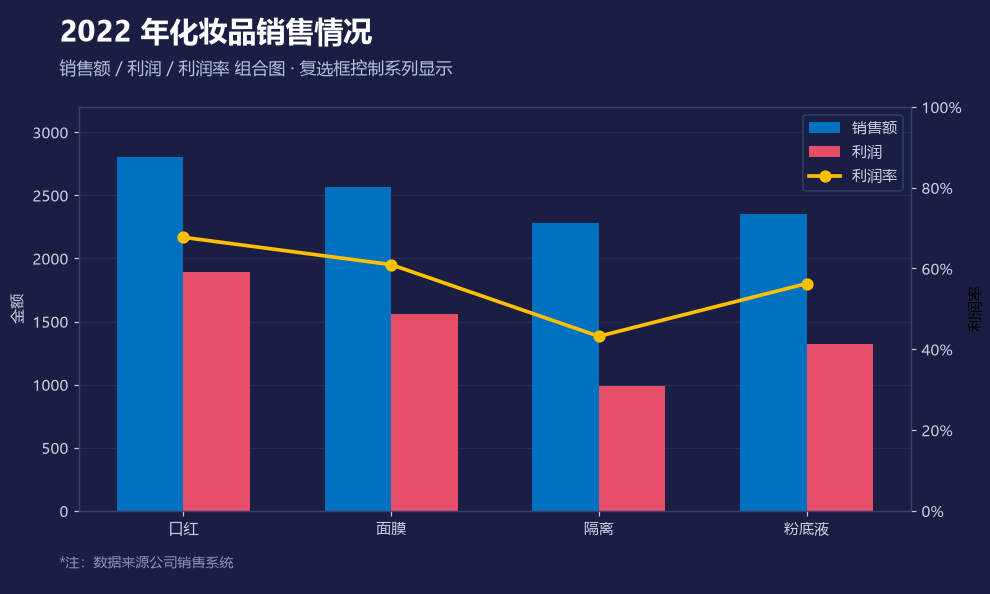

In [4]:
import numpy as np, pandas as pd, plotly.graph_objects as go, plotly, shutil, base64
from pathlib import Path
from IPython.display import HTML, display
BG,FG,GY,DIM,LINE='#1A1E43','#FFFFFF','#C9CFE3','#8B93B8','#39406F'
OUT=Path('interactive');OUT.mkdir(exist_ok=True)
if not (OUT/'plotly.min.js').exists(): shutil.copy(Path(plotly.__file__).parent/'package_data'/'plotly.min.js', OUT/'plotly.min.js')
def L(t,s,n,**kw):
    d=dict(paper_bgcolor=BG,plot_bgcolor=BG,height=620,
      font=dict(family='Microsoft YaHei, SimHei, sans-serif',color=GY,size=12),
      title=dict(text='<b>'+t+'</b><br><span style="font-size:13px;color:#B8C1DE">'+s+'</span>',x=.045,y=.935,xanchor='left',font=dict(color=FG,size=20)),
      margin=dict(l=70,r=45,t=118,b=82),
      hoverlabel=dict(bgcolor='#252B5C',bordercolor=LINE,font=dict(color=FG,size=12)),
      legend=dict(bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY)),
      annotations=[dict(text=n,x=0,y=-.17,xref='paper',yref='paper',showarrow=False,font=dict(color=DIM,size=10),xanchor='left')],
      transition=dict(duration=420,easing='cubic-in-out'))
    d.update(kw);return d
def A(**kw):
    d=dict(gridcolor=LINE,zerolinecolor=LINE,linecolor=LINE,tickfont=dict(color=GY),title=dict(font=dict(color=GY)),showgrid=True)
    d.update(kw);return d
def P():
    return dict(bgcolor=BG,angularaxis=dict(visible=False,showgrid=False,showline=False,direction='clockwise',rotation=0),
                radialaxis=dict(visible=False,showgrid=False,range=[0,1.06]))
def M(labels,args,active=0,x=1,y=1.13):
    return [dict(active=active,buttons=[dict(label=a,method='restyle',args=b) for a,b in zip(labels,args)],
      x=x,y=y,xanchor='right',bgcolor='#252B5C',bordercolor=LINE,borderwidth=1,font=dict(color=FG,size=11),pad=dict(l=6,r=6,t=3,b=3))]
def arc(v,vmax,i,c,lbl,step,width=15,n=44):
    w=180*v/vmax;th=[w*k/(n-1) for k in range(n)]
    return go.Scatterpolar(theta=th,r=[1-i*step]*n,mode='lines',line=dict(color=c,width=width),
      name=lbl,text=[lbl]*n,hovertemplate='%{text}<extra></extra>',showlegend=True)
def show(f,name):
    sh='<script>window.Plotly=window.Plotly||window.moduleName;</script>'
    cfg=dict(displaylogo=False,responsive=True,scrollZoom=True)
    frag=f.to_html(full_html=False,include_plotlyjs=False,config=cfg,div_id='p'+name)
    lib=(OUT/'plotly.min.js').read_text(encoding='utf-8')
    full='<!doctype html><html><head><meta charset="utf-8"><script>'+lib+'</script>'+sh+'<style>body{margin:0;background:'+BG+'}</style></head><body>'+frag+'</body></html>'
    (OUT/('ix'+name+'.html')).write_text(full,encoding='utf-8')
    p=Path('dyn'+name+'.png')
    im='<img src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'" style="width:100%;max-width:1000px;display:block">' if p.exists() else ''
    tip='<div style="color:#B8C1DE;font:12px Microsoft YaHei;padding:9px">交互版：interactive/ix'+name+'.html ｜ 用浏览器打开 dashboard.html 可切换全部 7 张交互图</div>'
    h=('<div style="background:'+BG+';padding:6px;border-radius:8px;position:relative">'
       '<div id="iv'+name+'"><script src="interactive/plotly.min.js"></script>'+sh+frag+'</div>'
       '<div id="fb'+name+'" style="position:absolute;top:0;left:0;right:0;background:'+BG+'">'+im+tip+'</div></div>'
       '<script>setTimeout(function(){var f=document.getElementById("fb'+name+'");'
       'if(f&&document.querySelector("#iv'+name+' .main-svg"))f.style.display="none"},700)</script>')
    display(HTML(h))
CAT=['口红','面膜','隔离','粉底液']
SALE=[2800,2564,2282,2353];PROF=[1896,1563,986,1324]
RATE=[p/s for p,s in zip(PROF,SALE)]
f=go.Figure()
f.add_trace(go.Bar(x=CAT,y=SALE,name='销售额',marker_color='#0070C0',hovertemplate='销售额 ¥%{y:,.0f}<extra></extra>'))
f.add_trace(go.Bar(x=CAT,y=PROF,name='利润',marker_color='#E74E69',hovertemplate='利润 ¥%{y:,.0f}<extra></extra>'))
f.add_trace(go.Scatter(x=CAT,y=RATE,name='利润率',yaxis='y2',mode='lines+markers',
  line=dict(color='#FFC000',width=3),marker=dict(size=10,color='#FFC000',line=dict(color=BG,width=2)),
  hovertemplate='利润率 %{y:.1%}<extra></extra>'))
f.update_layout(L('2022 年化妆品销售情况','点击图例或下方预设按钮 · 复选框控制系列显示','*注：数据来源公司销售系统',
  barmode='group',hovermode='x unified',xaxis=A(showgrid=False,title='品类'),
  yaxis=A(title='金额',range=[0,3200],gridcolor=LINE),
  yaxis2=dict(overlaying='y',side='right',range=[0,1],tickformat='.0%',showgrid=False,
    tickfont=dict(color='#FFC000'),title=dict(text='利润率',font=dict(color='#FFC000')),linecolor=LINE),
  legend=dict(orientation='h',x=1,y=1.13,xanchor='right',bgcolor='rgba(0,0,0,0)',borderwidth=0,font=dict(color=GY)),
  updatemenus=M(['全部显示','仅销售额','仅利润','仅利润率'],
    [[{'visible':[a,b,c]},[0,1,2]] for a,b,c in [(True,True,True),(True,False,False),(False,True,False),(False,False,True)]],
    x=0,y=1.13)))
f.layout.updatemenus[0].update(xanchor='left')
show(f,'04')



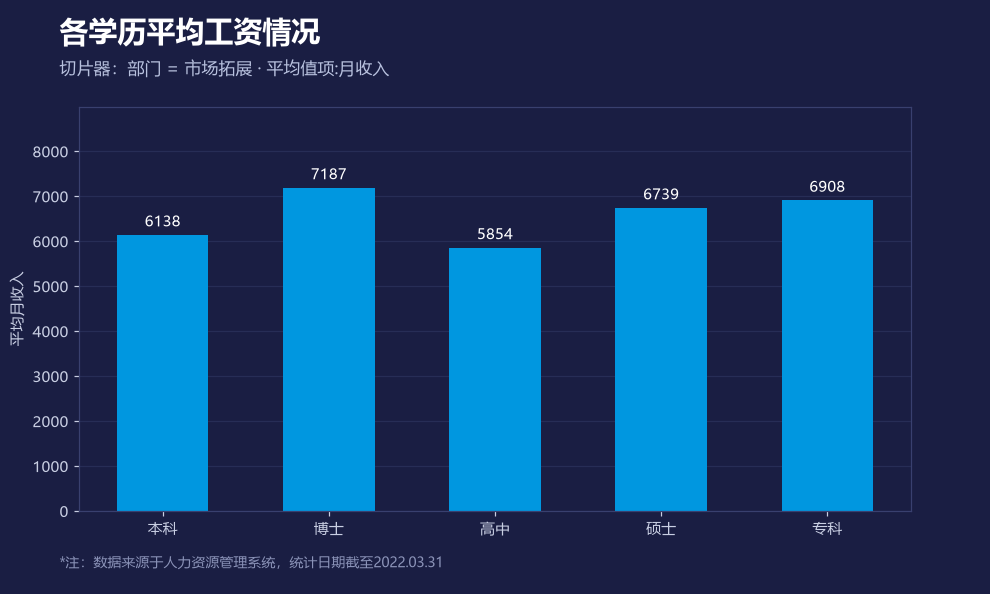

In [5]:
import numpy as np, pandas as pd, plotly.graph_objects as go, plotly, shutil, base64
from pathlib import Path
from IPython.display import HTML, display
BG,FG,GY,DIM,LINE='#1A1E43','#FFFFFF','#C9CFE3','#8B93B8','#39406F'
OUT=Path('interactive');OUT.mkdir(exist_ok=True)
if not (OUT/'plotly.min.js').exists(): shutil.copy(Path(plotly.__file__).parent/'package_data'/'plotly.min.js', OUT/'plotly.min.js')
def L(t,s,n,**kw):
    d=dict(paper_bgcolor=BG,plot_bgcolor=BG,height=620,
      font=dict(family='Microsoft YaHei, SimHei, sans-serif',color=GY,size=12),
      title=dict(text='<b>'+t+'</b><br><span style="font-size:13px;color:#B8C1DE">'+s+'</span>',x=.045,y=.935,xanchor='left',font=dict(color=FG,size=20)),
      margin=dict(l=70,r=45,t=118,b=82),
      hoverlabel=dict(bgcolor='#252B5C',bordercolor=LINE,font=dict(color=FG,size=12)),
      legend=dict(bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY)),
      annotations=[dict(text=n,x=0,y=-.17,xref='paper',yref='paper',showarrow=False,font=dict(color=DIM,size=10),xanchor='left')],
      transition=dict(duration=420,easing='cubic-in-out'))
    d.update(kw);return d
def A(**kw):
    d=dict(gridcolor=LINE,zerolinecolor=LINE,linecolor=LINE,tickfont=dict(color=GY),title=dict(font=dict(color=GY)),showgrid=True)
    d.update(kw);return d
def P():
    return dict(bgcolor=BG,angularaxis=dict(visible=False,showgrid=False,showline=False,direction='clockwise',rotation=0),
                radialaxis=dict(visible=False,showgrid=False,range=[0,1.06]))
def M(labels,args,active=0,x=1,y=1.13):
    return [dict(active=active,buttons=[dict(label=a,method='restyle',args=b) for a,b in zip(labels,args)],
      x=x,y=y,xanchor='right',bgcolor='#252B5C',bordercolor=LINE,borderwidth=1,font=dict(color=FG,size=11),pad=dict(l=6,r=6,t=3,b=3))]
def arc(v,vmax,i,c,lbl,step,width=15,n=44):
    w=180*v/vmax;th=[w*k/(n-1) for k in range(n)]
    return go.Scatterpolar(theta=th,r=[1-i*step]*n,mode='lines',line=dict(color=c,width=width),
      name=lbl,text=[lbl]*n,hovertemplate='%{text}<extra></extra>',showlegend=True)
def show(f,name):
    sh='<script>window.Plotly=window.Plotly||window.moduleName;</script>'
    cfg=dict(displaylogo=False,responsive=True,scrollZoom=True)
    frag=f.to_html(full_html=False,include_plotlyjs=False,config=cfg,div_id='p'+name)
    lib=(OUT/'plotly.min.js').read_text(encoding='utf-8')
    full='<!doctype html><html><head><meta charset="utf-8"><script>'+lib+'</script>'+sh+'<style>body{margin:0;background:'+BG+'}</style></head><body>'+frag+'</body></html>'
    (OUT/('ix'+name+'.html')).write_text(full,encoding='utf-8')
    p=Path('dyn'+name+'.png')
    im='<img src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'" style="width:100%;max-width:1000px;display:block">' if p.exists() else ''
    tip='<div style="color:#B8C1DE;font:12px Microsoft YaHei;padding:9px">交互版：interactive/ix'+name+'.html ｜ 用浏览器打开 dashboard.html 可切换全部 7 张交互图</div>'
    h=('<div style="background:'+BG+';padding:6px;border-radius:8px;position:relative">'
       '<div id="iv'+name+'"><script src="interactive/plotly.min.js"></script>'+sh+frag+'</div>'
       '<div id="fb'+name+'" style="position:absolute;top:0;left:0;right:0;background:'+BG+'">'+im+tip+'</div></div>'
       '<script>setTimeout(function(){var f=document.getElementById("fb'+name+'");'
       'if(f&&document.querySelector("#iv'+name+' .main-svg"))f.style.display="none"},700)</script>')
    display(HTML(h))
EDU=['本科','博士','高中','硕士','专科']
DEPT=['市场拓展','人力资源','后勤','工程','行政','财务','销售']
MAT={'全部':[6517,8278,5641,6832,6227],'市场拓展':[6138,7187,5854,6739,6908],
     '人力资源':[6761,4990,2777,9711,4489],'后勤':[0,0,2693,0,0],'工程':[0,0,3468,0,0],
     '行政':[6297,10035,6289,5696,5036],'财务':[6569,4317,3614,7413,3468],'销售':[7155,8839,5627,7305,6519]}
DF=pd.read_csv('hr_data.csv') if Path('hr_data.csv').exists() else None
def vals(d):
    if DF is None: return MAT.get(d,MAT['全部'])
    q=DF if d=='全部' else DF[DF['部门']==d]
    g=q.groupby('学历')['月收入'].mean()
    return [float(g.get(e,0)) for e in EDU]
OPT=['全部']+DEPT
y0=vals('市场拓展')
f=go.Figure(go.Bar(x=EDU,y=y0,marker_color='#0097E0',marker_line=dict(color='#00C2FF',width=1),
  text=[format(q,'.0f') for q in y0],textposition='outside',textfont=dict(color=FG,size=11),
  hovertemplate='<b>%{x}</b><br>平均月收入 ¥%{y:,.0f}<extra></extra>',name='平均月收入'))
f.update_layout(L('各学历平均工资情况','切片器：选择部门 · 平均值项:月收入','*注：数据来源于人力资源管理系统，统计日期截至2022.03.31',
  xaxis=A(showgrid=False,title='学历'),yaxis=A(title='平均月收入',range=[0,max(max(vals(d)) for d in OPT)*1.2]),
  hovermode='x',showlegend=False,
  updatemenus=M(OPT,[[{'y':[vals(d)],'text':[[format(q,'.0f') for q in vals(d)]]},[0]] for d in OPT],active=1)))
show(f,'05')



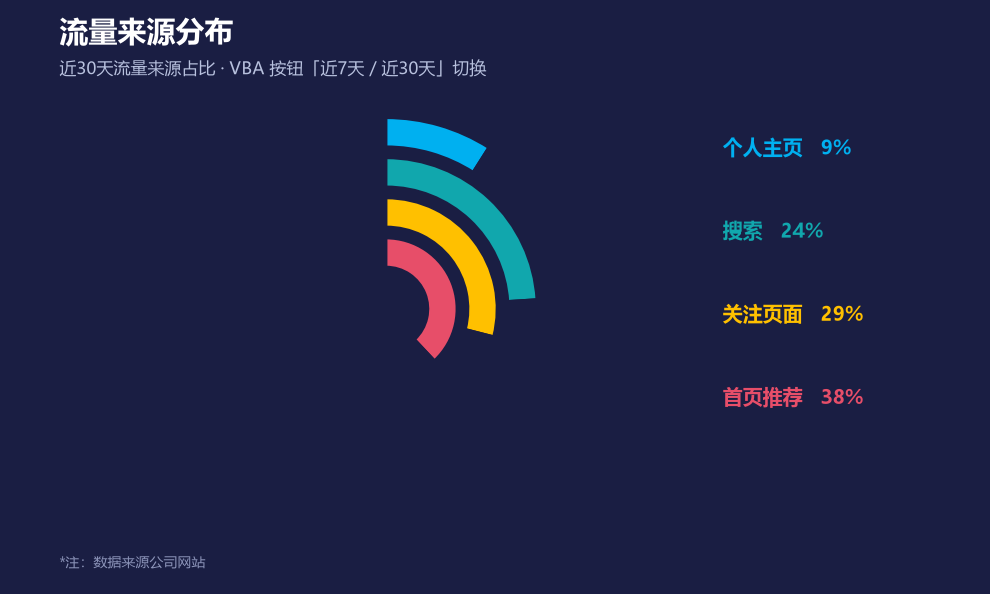

In [6]:
import numpy as np, pandas as pd, plotly.graph_objects as go, plotly, shutil, base64
from pathlib import Path
from IPython.display import HTML, display
BG,FG,GY,DIM,LINE='#1A1E43','#FFFFFF','#C9CFE3','#8B93B8','#39406F'
OUT=Path('interactive');OUT.mkdir(exist_ok=True)
if not (OUT/'plotly.min.js').exists(): shutil.copy(Path(plotly.__file__).parent/'package_data'/'plotly.min.js', OUT/'plotly.min.js')
def L(t,s,n,**kw):
    d=dict(paper_bgcolor=BG,plot_bgcolor=BG,height=620,
      font=dict(family='Microsoft YaHei, SimHei, sans-serif',color=GY,size=12),
      title=dict(text='<b>'+t+'</b><br><span style="font-size:13px;color:#B8C1DE">'+s+'</span>',x=.045,y=.935,xanchor='left',font=dict(color=FG,size=20)),
      margin=dict(l=70,r=45,t=118,b=82),
      hoverlabel=dict(bgcolor='#252B5C',bordercolor=LINE,font=dict(color=FG,size=12)),
      legend=dict(bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY)),
      annotations=[dict(text=n,x=0,y=-.17,xref='paper',yref='paper',showarrow=False,font=dict(color=DIM,size=10),xanchor='left')],
      transition=dict(duration=420,easing='cubic-in-out'))
    d.update(kw);return d
def A(**kw):
    d=dict(gridcolor=LINE,zerolinecolor=LINE,linecolor=LINE,tickfont=dict(color=GY),title=dict(font=dict(color=GY)),showgrid=True)
    d.update(kw);return d
def P():
    return dict(bgcolor=BG,angularaxis=dict(visible=False,showgrid=False,showline=False,direction='clockwise',rotation=0),
                radialaxis=dict(visible=False,showgrid=False,range=[0,1.06]))
def M(labels,args,active=0,x=1,y=1.13):
    return [dict(active=active,buttons=[dict(label=a,method='restyle',args=b) for a,b in zip(labels,args)],
      x=x,y=y,xanchor='right',bgcolor='#252B5C',bordercolor=LINE,borderwidth=1,font=dict(color=FG,size=11),pad=dict(l=6,r=6,t=3,b=3))]
def arc(v,vmax,i,c,lbl,step,width=15,n=44):
    w=180*v/vmax;th=[w*k/(n-1) for k in range(n)]
    return go.Scatterpolar(theta=th,r=[1-i*step]*n,mode='lines',line=dict(color=c,width=width),
      name=lbl,text=[lbl]*n,hovertemplate='%{text}<extra></extra>',showlegend=True)
def show(f,name):
    sh='<script>window.Plotly=window.Plotly||window.moduleName;</script>'
    cfg=dict(displaylogo=False,responsive=True,scrollZoom=True)
    frag=f.to_html(full_html=False,include_plotlyjs=False,config=cfg,div_id='p'+name)
    lib=(OUT/'plotly.min.js').read_text(encoding='utf-8')
    full='<!doctype html><html><head><meta charset="utf-8"><script>'+lib+'</script>'+sh+'<style>body{margin:0;background:'+BG+'}</style></head><body>'+frag+'</body></html>'
    (OUT/('ix'+name+'.html')).write_text(full,encoding='utf-8')
    p=Path('dyn'+name+'.png')
    im='<img src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'" style="width:100%;max-width:1000px;display:block">' if p.exists() else ''
    tip='<div style="color:#B8C1DE;font:12px Microsoft YaHei;padding:9px">交互版：interactive/ix'+name+'.html ｜ 用浏览器打开 dashboard.html 可切换全部 7 张交互图</div>'
    h=('<div style="background:'+BG+';padding:6px;border-radius:8px;position:relative">'
       '<div id="iv'+name+'"><script src="interactive/plotly.min.js"></script>'+sh+frag+'</div>'
       '<div id="fb'+name+'" style="position:absolute;top:0;left:0;right:0;background:'+BG+'">'+im+tip+'</div></div>'
       '<script>setTimeout(function(){var f=document.getElementById("fb'+name+'");'
       'if(f&&document.querySelector("#iv'+name+' .main-svg"))f.style.display="none"},700)</script>')
    display(HTML(h))
SRC=['个人主页','搜索','关注页面','首页推荐']
Q={'近7天':[.13,.19,.32,.36],'近30天':[.09,.24,.29,.38]}
CL=['#00B0F0','#11A7AD','#FFC000','#E74E69']
def pack(k): return [arc(Q[k][i],.5,i,CL[i],SRC[i]+'  '+format(Q[k][i],'.0%'),.21,18) for i in range(4)]
f=go.Figure(pack('近30天'),layout=L('流量来源分布','下拉框切换周期 · VBA 按钮「近7天 / 近30天」',
  '*注：数据来源公司网站',height=700,margin=dict(l=40,r=40,t=100,b=72),polar=P(),showlegend=True,
  legend=dict(x=.99,y=.9,bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY,size=11)),
  updatemenus=M(['近7天','近30天'],[[{'theta':[q.theta for q in pack(k)],'text':[q.text for q in pack(k)],'name':[q.name for q in pack(k)]},[0,1,2,3]] for k in ['近7天','近30天']],active=1)))
show(f,'06')



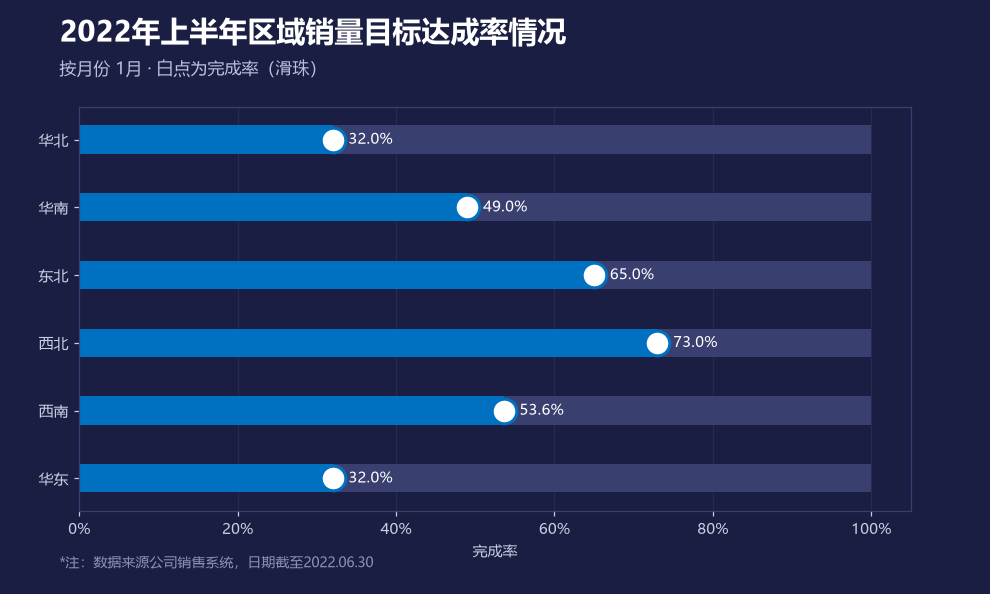

In [7]:
import numpy as np, pandas as pd, plotly.graph_objects as go, plotly, shutil, base64
from pathlib import Path
from IPython.display import HTML, display
BG,FG,GY,DIM,LINE='#1A1E43','#FFFFFF','#C9CFE3','#8B93B8','#39406F'
OUT=Path('interactive');OUT.mkdir(exist_ok=True)
if not (OUT/'plotly.min.js').exists(): shutil.copy(Path(plotly.__file__).parent/'package_data'/'plotly.min.js', OUT/'plotly.min.js')
def L(t,s,n,**kw):
    d=dict(paper_bgcolor=BG,plot_bgcolor=BG,height=620,
      font=dict(family='Microsoft YaHei, SimHei, sans-serif',color=GY,size=12),
      title=dict(text='<b>'+t+'</b><br><span style="font-size:13px;color:#B8C1DE">'+s+'</span>',x=.045,y=.935,xanchor='left',font=dict(color=FG,size=20)),
      margin=dict(l=70,r=45,t=118,b=82),
      hoverlabel=dict(bgcolor='#252B5C',bordercolor=LINE,font=dict(color=FG,size=12)),
      legend=dict(bgcolor='rgba(26,30,67,.82)',bordercolor=LINE,borderwidth=1,font=dict(color=GY)),
      annotations=[dict(text=n,x=0,y=-.17,xref='paper',yref='paper',showarrow=False,font=dict(color=DIM,size=10),xanchor='left')],
      transition=dict(duration=420,easing='cubic-in-out'))
    d.update(kw);return d
def A(**kw):
    d=dict(gridcolor=LINE,zerolinecolor=LINE,linecolor=LINE,tickfont=dict(color=GY),title=dict(font=dict(color=GY)),showgrid=True)
    d.update(kw);return d
def P():
    return dict(bgcolor=BG,angularaxis=dict(visible=False,showgrid=False,showline=False,direction='clockwise',rotation=0),
                radialaxis=dict(visible=False,showgrid=False,range=[0,1.06]))
def M(labels,args,active=0,x=1,y=1.13):
    return [dict(active=active,buttons=[dict(label=a,method='restyle',args=b) for a,b in zip(labels,args)],
      x=x,y=y,xanchor='right',bgcolor='#252B5C',bordercolor=LINE,borderwidth=1,font=dict(color=FG,size=11),pad=dict(l=6,r=6,t=3,b=3))]
def arc(v,vmax,i,c,lbl,step,width=15,n=44):
    w=180*v/vmax;th=[w*k/(n-1) for k in range(n)]
    return go.Scatterpolar(theta=th,r=[1-i*step]*n,mode='lines',line=dict(color=c,width=width),
      name=lbl,text=[lbl]*n,hovertemplate='%{text}<extra></extra>',showlegend=True)
def show(f,name):
    sh='<script>window.Plotly=window.Plotly||window.moduleName;</script>'
    cfg=dict(displaylogo=False,responsive=True,scrollZoom=True)
    frag=f.to_html(full_html=False,include_plotlyjs=False,config=cfg,div_id='p'+name)
    lib=(OUT/'plotly.min.js').read_text(encoding='utf-8')
    full='<!doctype html><html><head><meta charset="utf-8"><script>'+lib+'</script>'+sh+'<style>body{margin:0;background:'+BG+'}</style></head><body>'+frag+'</body></html>'
    (OUT/('ix'+name+'.html')).write_text(full,encoding='utf-8')
    p=Path('dyn'+name+'.png')
    im='<img src="data:image/png;base64,'+base64.b64encode(p.read_bytes()).decode()+'" style="width:100%;max-width:1000px;display:block">' if p.exists() else ''
    tip='<div style="color:#B8C1DE;font:12px Microsoft YaHei;padding:9px">交互版：interactive/ix'+name+'.html ｜ 用浏览器打开 dashboard.html 可切换全部 7 张交互图</div>'
    h=('<div style="background:'+BG+';padding:6px;border-radius:8px;position:relative">'
       '<div id="iv'+name+'"><script src="interactive/plotly.min.js"></script>'+sh+frag+'</div>'
       '<div id="fb'+name+'" style="position:absolute;top:0;left:0;right:0;background:'+BG+'">'+im+tip+'</div></div>'
       '<script>setTimeout(function(){var f=document.getElementById("fb'+name+'");'
       'if(f&&document.querySelector("#iv'+name+' .main-svg"))f.style.display="none"},700)</script>')
    display(HTML(h))
REG=['华北','华南','东北','西北','西南','华东']
MO=['1月','2月','3月','4月','5月','6月']
R=[[.32,.45,.66,.52,.69,.771],[.49,.36,.54,.39,.415,.403],[.65,.53,.58,.48,.445,.399],
   [.73,.63,.61,.53,.47,.408],[.536,.498,.527,.708,.7035,.758],[.32,.49,.65,.73,.536,.7468]]
OPT=[('按月份',m) for m in MO]+[('按区域',r) for r in REG]
def val(mode,item): return [R[i][MO.index(item)] for i in range(6)] if mode=='按月份' else R[REG.index(item)]
def lab(mode,item): return REG if mode=='按月份' else MO
v0=val('按月份','1月');l0=lab('按月份','1月')
f=go.Figure()
f.add_trace(go.Bar(y=l0,x=v0,orientation='h',marker_color='#0070C0',width=.42,name='完成率',
  hovertemplate='完成率 %{x:.1%}<extra></extra>',showlegend=False))
f.add_trace(go.Bar(y=l0,x=[1-q for q in v0],orientation='h',base=v0,marker_color='#39406F',width=.42,
  name='未完成',hoverinfo='skip',showlegend=False))
f.add_trace(go.Scatter(y=l0,x=v0,mode='markers+text',text=[format(q,'.1%') for q in v0],
  textposition='middle right',textfont=dict(color=FG,size=11),
  marker=dict(size=20,color=FG,line=dict(color='#0070C0',width=3)),name='滑珠',
  hovertemplate='<b>%{y}</b><br>完成率 %{x:.1%}<extra></extra>',showlegend=False))
f.update_layout(L('2022年上半年区域销量目标达成率情况','下拉框切换「按月份 / 按区域」· 白点为完成率（滑珠）',
  '*注：数据来源公司销售系统，日期截至2022.06.30',
  barmode='stack',xaxis=A(title='完成率',range=[0,1.12],tickformat='.0%',gridcolor=LINE),
  yaxis=A(showgrid=False,categoryorder='array',categoryarray=l0[::-1],title=''),
  hovermode='y unified',showlegend=False,barnorm=None,
  updatemenus=M(['按月份 '+m for m in MO]+['按区域 '+r for r in REG],
    [[{'x':[val(*o),[1-q for q in val(*o)],val(*o)],'y':[lab(*o),lab(*o),lab(*o)],
       'text':[[],[],[format(q,'.1%') for q in val(*o)]]},[0,1,2]] for o in OPT])))
show(f,'07')


In [8]:
import re
from IPython.display import HTML, display
from pathlib import Path
FS=sorted(Path('interactive').glob('ix*.html'))
NAMES=['动态柱形图','动态跑道图','南丁格尔圆环图','动态组合图','透视表切片器','VBA 动态玉玦图','动态滑珠图']
if len(FS)<7:
    display(HTML('<p style="color:#FFC000">请先运行前 7 个 cell 以生成交互图文件</p>'))
else:
    parts=[]
    for p in FS:
        h=p.read_text(encoding='utf-8')
        m=re.search(r'(<div[^>]*id="p\d\d".*?</script>)',h,re.S)
        if m: parts.append(m.group(1))
    lib=Path('interactive/plotly.min.js').read_text(encoding='utf-8')
    inline='<script>'+lib+'</script><script>window.Plotly=window.Plotly||window.moduleName;</script>'
    btn=''.join('<button class="b" onclick="tab(%d)">%02d %s</button>'%(i,i+1,n) for i,n in enumerate(NAMES))
    panes=''.join('<div class="pane" id="t%d">%s</div>'%(i,s) for i,s in enumerate(parts))
    css='body{margin:0;background:#0E1228;color:#C9CFE3;font-family:Microsoft YaHei,sans-serif}header{padding:22px 34px 8px;background:linear-gradient(90deg,#1A1E43,#252B5C);border-bottom:2px solid #FFC000}header h1{margin:0;color:#fff;font-size:23px}header p{margin:6px 0 0;color:#B8C1DE;font-size:13px}nav{padding:14px 34px;display:flex;flex-wrap:wrap;gap:8px;background:#141833}.b{background:#252B5C;color:#C9CFE3;border:1px solid #39406F;border-radius:18px;padding:7px 15px;font-size:12px;cursor:pointer}.b:hover,.b.on{background:#FFC000;color:#1A1E43;border-color:#FFC000;font-weight:700}.pane{padding:8px 24px 30px;background:#1A1E43;min-height:620px}'
    js='function tab(i){for(var j=0;j<7;j++){document.getElementById("t"+j).style.display=j==i?"block":"none"}var b=document.getElementsByClassName("b");for(var j=0;j<b.length;j++){b[j].className=j==i?"b on":"b"}if(window.Plotly){var d=document.getElementById("p0"+(i+1));if(d)Plotly.Plots.resize(d)}}tab(0);'
    err="<div id='err' style='display:none;background:#8E2B2B;color:#fff;padding:10px 18px;font:13px sans-serif'></div><script>window.addEventListener('error',function(e){var d=document.getElementById('err');if(d){d.style.display='block';d.textContent='脚本执行出错：'+e.message}});</script>"
    html='<!doctype html><html><head><meta charset="utf-8"><title>动态图表 · 交互总控面板</title>'+inline+'<style>'+css+'</style></head><body>'+err+'<header><h1>Excel 动态图表 · Python 交互复现</h1><p>7 个案例 · Plotly 原生交互 · 悬停查看数值 / 框选缩放 / 图例开关 / 下拉与滑块切换 / 播放动画</p></header><nav>'+btn+'</nav>'+panes+'<script>'+js+'</script></body></html>'
    Path('dashboard.html').write_text(html,encoding='utf-8')
    Path('interactive/dashboard.html').write_text(html,encoding='utf-8')
    display(HTML('<div style="background:#141833;padding:14px 18px;border-radius:8px;color:#C9CFE3;font:13px Microsoft YaHei;border-left:4px solid #FFC000">已生成 <b style="color:#FFC000">dashboard.html</b>（单文件自包含 · 双击用浏览器打开）<br>7 张交互图已内嵌；若此处输出区为空白是 Jupyter 禁用脚本所致，请用浏览器打开 dashboard.html</div>'))
